
Attribute Information:

1. **age**: continuous. 
2. **workclass**: Federal-gov, Local-gov, Never-worked, Private, Self-emp-inc, Slef-emp-not-inc, State-gov, Without-pay. 
3. **education**: Bachelors, Some-college, 11th, HS-grad, Prof-school, Assoc-acdm, Assoc-voc, 9th, 7th-8th, 12th, Masters, 1st-4th, 10th, Doctorate, 5th-6th, Preschool. 
4. **education-num**: continuous.(numerical representation of education) 
5. **marital-status**: Married-civ-spouse, Divorced, Never-married, Separated, Widowed, Married-spouse-absent, Married-AF-spouse. 
6. **occupation**: Tech-support, Craft-repair, Other-service, Sales, Exec-managerial, Prof-specialty, Handlers-cleaners, Machine-op-inspct, Adm-clerical, Farming-fishing, Transport-moving, Priv-house-serv, Protective-serv, Armed-Forces. 
7. **relationship**: Wife, Own-child, Husband, Not-in-family, Other-relative, Unmarried. 
8. **race**: White, Asian-Pac-Islander, Amer-Indian-Eskimo, Other, Black. 
9. **sex**: Female, Male. 
10. **capital-gain**: continuous. 
11. **capital-loss**: continuous. 
12. **hours-per-week**: continuous. 
13. **native-country**: United-States, Cambodia, England, Puerto-Rico, Canada, Germany, Outlying-US(Guam-USVI-etc), India, Japan, Greece, South, China, Cuba, Iran, Honduras, Philippines, Italy, Poland, Jamaica, Vietnam, Mexico, Portugal, Ireland, France, Dominican-Republic, Laos, Ecuador, Taiwan, Haiti, Columbia, Hungary, Guatemala, Nicaragua, Scotland, Thailand, Yugoslavia, El-Salvador, Trinadad&Tobago, Peru, Hong, Holand-Netherlands.
14. **fnlwgt**: continuous.(how many entries this entry represents)

**IMPORTING LIBRARIES**

In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

**GET DATA AND PRINT HEAD**

In [ ]:
df = pd.read_csv(r'<path_to_csv_file>')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              32561 non-null  int64 
 1    workclass       32561 non-null  object
 2    fnlwgt          32561 non-null  int64 
 3    education       32561 non-null  object
 4    education-num   32561 non-null  int64 
 5    marital-status  32561 non-null  object
 6    occupation      32561 non-null  object
 7    relationship    32561 non-null  object
 8    race            32561 non-null  object
 9    sex             32561 non-null  object
 10   capital-gain    32561 non-null  int64 
 11   capital-loss    32561 non-null  int64 
 12   hours-per-week  32561 non-null  int64 
 13   native-country  32561 non-null  object
 14   income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


**LET'S REMOVE THE WHITESPACES IN OUR COLUMN TITLES**

In [4]:
df.columns = df.columns.str.strip()

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [8]:
list(df)

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education-num',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital-gain',
 'capital-loss',
 'hours-per-week',
 'native-country',
 'income']

In [10]:
my_columns = ['age',
 'workclass',
 'fnlwgt',
 'education',
 'education-num',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital-gain',
 'capital-loss',
 'hours-per-week',
 'native-country',
 'income']
for col in list(my_columns):
    print(f"--------------------{col.title()}-------------------------")
    total= df[col].value_counts()
    percent = df[col].value_counts() / df.shape[0]
    printdf = pd.concat([total],keys = ['total'],axis = 1)
    print(printdf)
    print('\n')

--------------------Age-------------------------
     total
age       
36     898
31     888
34     886
23     877
35     876
..     ...
83       6
88       3
85       3
86       1
87       1

[73 rows x 1 columns]


--------------------Workclass-------------------------
                  total
workclass              
Private           22696
Self-emp-not-inc   2541
Local-gov          2093
?                  1836
State-gov          1298
Self-emp-inc       1116
Federal-gov         960
Without-pay          14
Never-worked          7


--------------------Fnlwgt-------------------------
        total
fnlwgt       
164190     13
203488     13
123011     13
148995     12
121124     12
...       ...
232784      1
325573      1
140176      1
318264      1
257302      1

[21648 rows x 1 columns]


--------------------Education-------------------------
              total
education          
HS-grad       10501
Some-college   7291
Bachelors      5355
Masters        1723
Assoc-voc      1382
11th 

**WE HAVE SOME ? VALUES, LET'S REPLACE THEM WITH NaN**

In [13]:
df.replace(' ?', np.nan, inplace=True)

In [14]:
for col in list(my_columns):
    print(f"--------------------{col.title()}-------------------------")
    total= df[col].value_counts()
    percent = df[col].value_counts() / df.shape[0]
    printdf = pd.concat([total],keys = ['total'],axis = 1)
    print(printdf)
    print('\n')

--------------------Age-------------------------
     total
age       
36     898
31     888
34     886
23     877
35     876
..     ...
83       6
88       3
85       3
86       1
87       1

[73 rows x 1 columns]


--------------------Workclass-------------------------
                  total
workclass              
Private           22696
Self-emp-not-inc   2541
Local-gov          2093
State-gov          1298
Self-emp-inc       1116
Federal-gov         960
Without-pay          14
Never-worked          7


--------------------Fnlwgt-------------------------
        total
fnlwgt       
164190     13
203488     13
123011     13
148995     12
121124     12
...       ...
232784      1
325573      1
140176      1
318264      1
257302      1

[21648 rows x 1 columns]


--------------------Education-------------------------
              total
education          
HS-grad       10501
Some-college   7291
Bachelors      5355
Masters        1723
Assoc-voc      1382
11th           1175
Assoc-acd

**Let's merge some columns so we can try creating more informative features while reducing dimensionality**

In [22]:
hs_grad = [' HS-grad',' 11th',' 10th',' 9th',' 12th']
elementary = [' 1st-4th',' 5th-6th',' 7th-8th']

# replace elements in list.
df['education'].replace(to_replace = hs_grad,value = 'HS-grad',inplace = True)
df['education'].replace(to_replace = elementary,value = 'elementary_school',inplace = True)

df['education'].value_counts()

education
HS-grad              13556
 Some-college         7291
 Bachelors            5355
 Masters              1723
 Assoc-voc            1382
elementary_school     1147
 Assoc-acdm           1067
 Prof-school           576
 Doctorate             413
 Preschool              51
Name: count, dtype: int64

In [20]:
married= [' Married-spouse-absent',' Married-civ-spouse',' Married-AF-spouse']
separated = [' Separated',' Divorced']

df['marital-status'].replace(to_replace = married ,value = 'Married',inplace = True)
df['marital-status'].replace(to_replace = separated,value = 'Separated',inplace = True)

df['marital-status'].value_counts()

marital-status
Married           15417
 Never-married    10683
Separated          5468
 Widowed            993
Name: count, dtype: int64

In [21]:
self_employed = [' Self-emp-not-inc',' Self-emp-inc']
govt_employees = [' Local-gov',' State-gov',' Federal-gov']

df['workclass'].replace(to_replace = self_employed ,value = 'Self_employed',inplace = True)
df['workclass'].replace(to_replace = govt_employees,value = 'Govt_employees',inplace = True)

df['workclass'].value_counts()

workclass
 Private          22696
Govt_employees     4351
Self_employed      3657
 Without-pay         14
 Never-worked         7
Name: count, dtype: int64

**Visualize the income frequency**

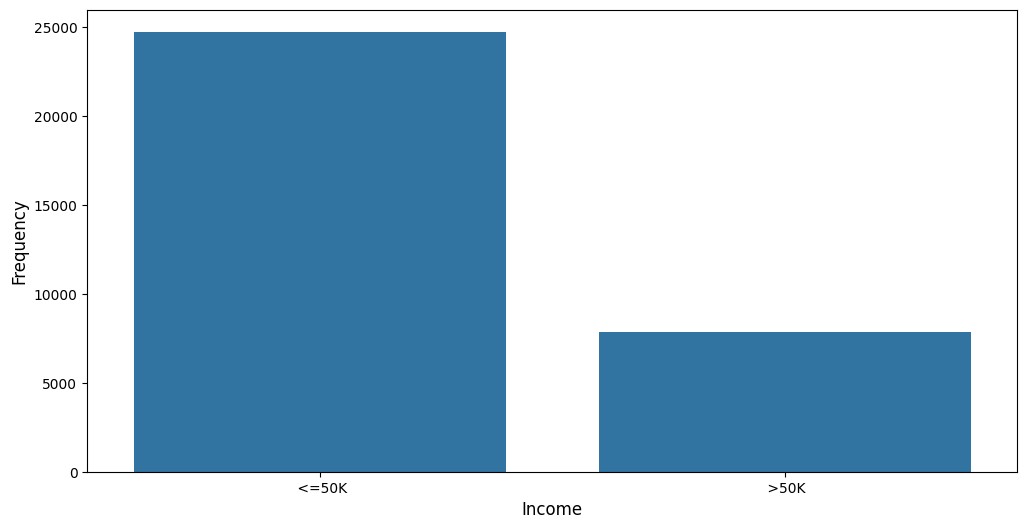

In [23]:
plt.figure(figsize =(12,6));
sns.countplot(x = 'income', data = df);
plt.xlabel("Income",fontsize = 12);
plt.ylabel("Frequency",fontsize = 12);

**Exploring distribution of numerical features**

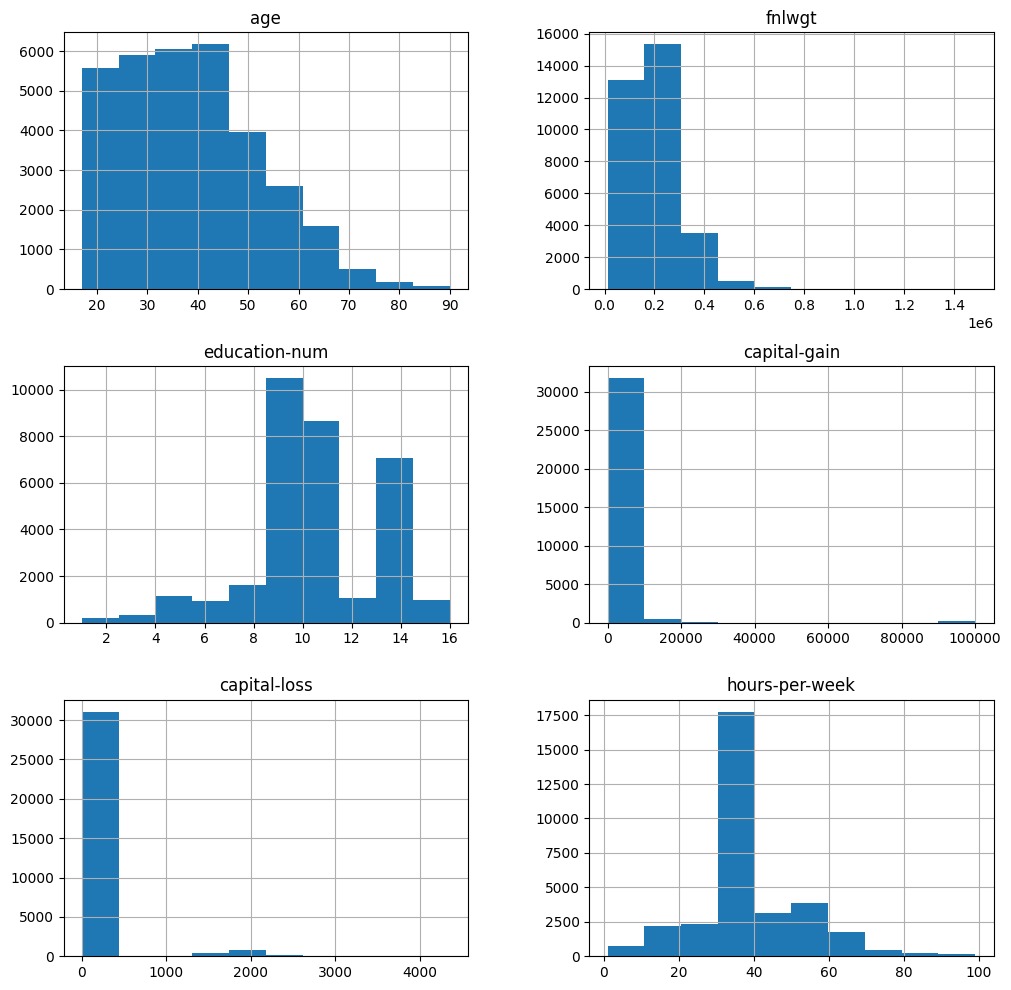

In [26]:
df[list(my_columns)].hist(figsize = (12,12));

**We can remove education-num because it gives us same information as education**

In [28]:
print(f"Number of columns before deleting: {df.shape[1]}")

deleted_cols = ['education-num']
df.drop(labels = deleted_cols,axis = 1,inplace = True)
print(f"Number of columns after deleting: {df.shape[1]}")

Number of columns before deleting: 15
Number of columns after deleting: 14


**Let's identify categorical features and target variable**

In [29]:
categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
target_variable = 'income'

**We can one-hot encode categorical features to avoid misleading ordinal interpretations, and potentially improve model performance by treating categories independently.**

In [30]:
encoded_data = pd.get_dummies(df, columns=categorical_features, drop_first=True)

**Label encode the target variable**

In [32]:
label_encoder = LabelEncoder()
encoded_data[target_variable] = label_encoder.fit_transform(encoded_data[target_variable])

In [33]:
X = encoded_data.drop(target_variable, axis=1)
y = encoded_data[target_variable]

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Instantiate the classifiers**

In [48]:
clf_tree = DecisionTreeClassifier()
clf_knn =  KNeighborsClassifier()
clf_forest = RandomForestClassifier()
clf_gnb = GaussianNB()

In [49]:
classifiers = ['DecisionTree', 'KNN', 'RandomForest', 'Naive']

In [50]:
models = {clf_tree:'DecisionTree',
          clf_knn: 'KNN',          
          clf_forest: 'RandomForest',          
          clf_gnb: 'Naive'}

**The train function fits the model and returns accuracy score**

In [51]:
def train(algo,name,X_train,y_train,X_test,y_test):
    algo.fit(X_train,y_train)
    y_pred = algo.predict(X_test)
    score = accuracy_score(y_test,y_pred)
    print(f"--------------------------------------------{name}---------------------------------------------------")
    print(f"Accuracy Score for {name}: {score*100:.4f}%")
    return y_test,y_pred,score

# acc_res function calculates confusion matrix
def acc_res(y_test,y_pred):
    null_accuracy = y_test.value_counts()[0]/len(y_test)
    print(f"Null Accuracy: {null_accuracy*100:.4f}%")
    print("Confusion Matrix")
    matrix = confusion_matrix(y_test,y_pred)
    print(matrix)
    print("+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    TN = matrix[0,0]
    FP = matrix[0,1]
    FN = matrix[1,0]
    TP = matrix[1,1]
    accuracy_score=(TN+TP) / float(TP+TN+FP+FN)
    recall_score = (TP)/ float(TP+FN)
    specificity = TN / float(TN+FP)
    FPR = FP / float(FP+TN)
    precision_score = TP / float(TP+FP)
    print(f"Accuracy Score: {accuracy_score*100:.4f}%")
    print(f"Recall Score: {recall_score*100:.4f}%")
    print(f"Specificity Score: {specificity*100:.4f}%")
    print(f"False Positive Rate: {FPR*100:.4f}%")
    print(f"Precision Score: {precision_score*100:.4f}%")
    print("+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++")
    print("Classification Report")
    print(classification_report(y_test,y_pred))
    
def main(models):
    accuracy_scores = []
    for algo,name in models.items():
        y_test_train,y_pred,acc_score = train(algo,name,X_train,y_train,X_test,y_test)
        acc_res(y_test_train,y_pred)
        accuracy_scores.append(acc_score)
    return accuracy_scores
    
accuracy_scores = main(models)    

--------------------------------------------DecisionTree---------------------------------------------------
Accuracy Score for DecisionTree: 81.0533%
Null Accuracy: 75.8790%
Confusion Matrix
[[4316  626]
 [ 608  963]]
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Accuracy Score: 81.0533%
Recall Score: 61.2985%
Specificity Score: 87.3331%
False Positive Rate: 12.6669%
Precision Score: 60.6042%
+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Classification Report
              precision    recall  f1-score   support

           0       0.88      0.87      0.87      4942
           1       0.61      0.61      0.61      1571

    accuracy                           0.81      6513
   macro avg       0.74      0.74      0.74      6513
weighted avg       0.81      0.81      0.81      6513

--------------------------------------------KNN---------------------------------------------------
Accuracy Score for KNN: 82.4812%
Null Accuracy: 75